# Réplica de la validación manual — LAG-028 / RDS 62

Ejecutar desde `entregas/bo`, con kernel R.

La entrada es `benchmark_multisemilla_lags20261009_200322-REPLICA`. El dataset, los meses, las semillas y las columnas excluidas son los de la validación manual original que produjo el RDS 62; se configuran en esta notebook.

Se conserva el código original que elige el mejor modelo del benchmark, construye sus parámetros, entrena y evalúa cada semilla. Se guardan `62-REPLICA.rds` y `validaciones_manuales_replica.csv` en `entregas/bo`.

# Librerias


In [1]:
# cargo las librerias que necesito
require("data.table")
require("parallel")

if(!require("R.utils")) install.packages("R.utils")
require("R.utils")

if( !require("primes") ) install.packages("primes")
require("primes")

if( !require("utils") ) install.packages("utils")
require("utils")

if( !require("rlist") ) install.packages("rlist")
require("rlist")

if( !require("yaml")) install.packages("yaml")
require("yaml")

if( !require("lightgbm") ) install.packages("lightgbm")
require("lightgbm")

if( !require("DiceKriging") ) install.packages("DiceKriging")
require("DiceKriging")

if( !require("mlrMBO") ) install.packages("mlrMBO")
require("mlrMBO")

library(here)
require("ggplot2")


Loading required package: data.table

Loading required package: parallel

Loading required package: R.utils

Loading required package: R.oo

Loading required package: R.methodsS3

R.methodsS3 v1.8.2 (2022-06-13 22:00:14 UTC) successfully loaded. See ?R.methodsS3 for help.

R.oo v1.27.1 (2025-05-02 21:00:05 UTC) successfully loaded. See ?R.oo for help.


Attaching package: ‘R.oo’


The following object is masked from ‘package:R.methodsS3’:

    throw


The following objects are masked from ‘package:methods’:

    getClasses, getMethods


The following objects are masked from ‘package:base’:

    attach, detach, load, save


R.utils v2.13.0 (2025-02-24 21:20:02 UTC) successfully loaded. See ?R.utils for help.


Attaching package: ‘R.utils’


The following object is masked from ‘package:utils’:

    timestamp


The following objects are masked from ‘package:base’:

    cat, commandArgs, getOption, isOpen, nullfile, parse, warnings


Loading required package: primes

Loading required packa

# URLS

In [2]:
# Ejecutar desde entregas/bo.
root <- getwd()
exp_folder <- root
data_folder <- file.path(dirname(root), "dataset")

dataset_file = 'RANKS_LF_O2_K6_P4.csv'
dataset_url <- file.path(data_folder, dataset_file)
list.files(data_folder)

carpeta_man_val <- root
archivo_validaciones <- file.path(
  carpeta_man_val,
  "validaciones_manuales_replica.csv"
)

SEEDS <- c(230047, 230059, 230063, 230077, 230081)
id_validacion <- '62-REPLICA'


[1] "c_01_tern_2_lags_O2.csv"                   
 [2] "c_01_tern_2_lags.csv"                      
 [3] "c_01_tern_2_lf_k6_p4.csv"                  
 [4] "c_01_tern_2_lf_O2_k3_p6.csv"               
 [5] "c_01_tern_2.csv"                           
 [6] "competencia_01_crudo.csv"                  
 [7] "competencia_01_ternaria_lags.csv"          
 [8] "competencia_01_ternaria_lf_k6_perdida4.csv"
 [9] "competencia_01_ternaria.csv"               
[10] "RANKS_LAGS_O2.csv"                         
[11] "RANKS_LF_O2_K6_P4.csv"                     
[12] "versiones_dataset_1.ipynb"                 
[13] "versiones_dataset_2.ipynb"

# LEEMOS DATASET

In [3]:
# leo el dataset
dataset <- fread(dataset_url)

In [4]:
setorder( dataset, foto_mes, ternaria, numero_de_cliente)
dataset[, .N, list(foto_mes, ternaria)]

foto_mes,ternaria,N
<int>,<chr>,<int>
202103,BAJA+1,1019
202103,BAJA+2,960
202103,continua,160921
202104,BAJA+1,964
202104,BAJA+2,1139
202104,continua,161181
202105,BAJA+1,1143
202105,BAJA+2,870
202105,continua,161755


In [5]:
# colnames(dataset)

# CLASE01


In [6]:
dataset[, clase01 := ifelse(ternaria %in% c("BAJA+1", "BAJA+2"), 1L, 0L)]

# Columnas a usar

In [7]:
grep("prestamos_personales", colnames(dataset), value = TRUE, ignore.case = TRUE)
grep("ternaria", colnames(dataset), value = TRUE, ignore.case = TRUE)

[1] "cprestamos_personales"               
[2] "mprestamos_personales"               
[3] "cprestamos_personales_lag_pond"      
[4] "mprestamos_personales_lag_pond"      
[5] "cprestamos_personales_delta_lag_pond"
[6] "mprestamos_personales_delta_lag_pond"

[1] "ternaria"

In [8]:
columnas_excluir <-
c(
    "ternaria",
    "ternaria_lag1",
    "ternaria_lag2",
    "clase01",
    "fold",
    "azar",
    "training",
    "cprestamos_personales",
    "cprestamos_personales_lag1",
    "cprestamos_personales_delta1",
    "cprestamos_personales_lag2",
    "cprestamos_personales_delta2",
    "cprestamos_personales_lag_pond",
    "cprestamos_personales_delta_lag_pond",
    "cprestamos_personales_lag_pond2",
    "cprestamos_personales_delta_lag_pond2",
    "mprestamos_personales",
    "mprestamos_personales_lag1",
    "mprestamos_personales_delta1",
    "mprestamos_personales_lag2",
    "mprestamos_personales_delta2",
    "mprestamos_personales_lag_pond",
    "mprestamos_personales_delta_lag_pond",
    "mprestamos_personales_lag_pond2",
    "mprestamos_personales_delta_lag_pond2"
  )

In [9]:
campos_buenos <- setdiff(
  colnames(dataset),
  columnas_excluir  
)

# Experimento


In [10]:
# Carpeta generada por la validación multisemilla replicada.
carpeta_benchmarks <- exp_folder
writeLines(list.files(carpeta_benchmarks, pattern = "benchmark"))


benchmark_multisemilla_lags20260924_114539
benchmark_multisemilla_lags20261009_200322
benchmark_multisemilla_lags20261009_200322-r
diagnostico_benchmark_lag028_dt1148
diagnostico_benchmark_lag028_dt1148.ipynb


In [ ]:
benchmark_base <- "benchmark_multisemilla_lags20261009_200322-REPLICA"


## Parametros

In [12]:

carpeta_benchmark <-file.path(
  carpeta_benchmarks,
  benchmark_base
)

In [13]:
train <- c(202103, 202104)
train_final <- c(202103, 202104)
future <- c(202106)

In [14]:

# Configuración utilizada durante la validación
PARAM_BENCH <- readRDS(
  file.path(carpeta_benchmark, "PARAM.rds")
)

# Lee los mejores resultados y selecciona el de mayor ganancia promedio
mejor_modelo <- data.table::fread(
  file.path(carpeta_benchmark, "mejor_corte_por_modelo.tsv")
)[which.max(ganancia_total_promedio)]

# Identifica qué columnas de la fila corresponden a parámetros de LightGBM
columnas_parametros <- intersect(
  names(PARAM_BENCH$lgbm$param_fijos),
  names(mejor_modelo)
)

# Combina los parámetros fijos con los del mejor modelo
params_completos <- modifyList(
  PARAM_BENCH$lgbm$param_fijos,
  as.list(mejor_modelo[, ..columnas_parametros])
)

# Ajusta min_data_in_leaf según el undersampling usado
params_completos$min_data_in_leaf <- round(
  params_completos$min_data_in_leaf /
    PARAM_BENCH$trainingstrategy$undersampling
)


In [15]:
cortes <-PARAM_BENCH$cortes

In [16]:
getwd()
ruta <- file.path(carpeta_benchmark, "PARAM.rds")
ruta
file.exists(ruta)
file.access(ruta, 4)

[1] "/home/marco/code/DMEyF/dmeyf2026/entregas/bo"

[1] "/home/marco/code/DMEyF/dmeyf2026/entregas/bo/benchmark_multisemilla_lags20261009_200322-r/PARAM.rds"

[1] TRUE

/home/marco/code/DMEyF/dmeyf2026/entregas/bo/benchmark_multisemilla_lags20261009_200322-r/PARAM.rds 
                                                                                                  0

In [17]:
list.files(exp_folder, pattern = "^benchmark_multisemilla")
list.files(carpeta_benchmark)

[1] "benchmark_multisemilla_lags20260924_114539"  
[2] "benchmark_multisemilla_lags20261009_200322"  
[3] "benchmark_multisemilla_lags20261009_200322-r"

[1] "mejor_corte_por_modelo.tsv" "PARAM.rds"

## Dataset train y test

In [18]:
dataset_train <- dataset[foto_mes %in% train_final]
dataset_train[,.N, list(foto_mes, ternaria)]

foto_mes,ternaria,N
<int>,<chr>,<int>
202103,BAJA+1,1019
202103,BAJA+2,960
202103,continua,160921
202104,BAJA+1,964
202104,BAJA+2,1139
202104,continua,161181


In [19]:
# aplico el modelo a los datos sin clase
dfuture <- dataset[foto_mes %in% future]

# Entreno

In [20]:
ganancias_semillas <- numeric(length(SEEDS))
curvas_semillas <- vector("list", length(SEEDS))
params_por_semilla <- setNames(vector("list", length(SEEDS)), as.character(SEEDS))

for (i in seq_along(SEEDS)) {
  params_semilla <- params_completos
  params_semilla$seed <- SEEDS[i]
  params_por_semilla[[i]] <- params_semilla

  dtrain_final <- lgb.Dataset(
    data= data.matrix(dataset_train[, campos_buenos, with= FALSE]),
    label= dataset_train[, clase01]
  )

  modelo_final <- lgb.train(
    data= dtrain_final,
    param= params_semilla
  )

  # hago el predict en los datos del futuro, y calculo la ganancia

  # aplico el modelo a los datos nuevos
  prediccion <- predict(
    modelo_final,
    data.matrix(dfuture[, campos_buenos, with= FALSE])
  )

  # calculo la ganancia en los datos ddel futuro para todos los cortes
  tb_prediccion <- dfuture[, list(numero_de_cliente, foto_mes,ternaria)]
  tb_prediccion[, prob := prediccion ]
  tb_prediccion[, gan := ifelse(ternaria == "BAJA+2", 1072500, -27500)]

  # lgb.save(modelo_final, "modelo.txt" )
  # Dibujo la curva de ganancia acumulada
  setorder(tb_prediccion, -prob)
  tb_prediccion[, ganancia_acumulada := cumsum(gan)]
  tb_prediccion[, pos := sequence(.N)]

  print(tb_prediccion|> head())

  ganancias_semillas[i] <- max(tb_prediccion$ganancia_acumulada)
  curvas_semillas[[i]] <- tb_prediccion[, list(
    pos, ganancia_acumulada, seed = SEEDS[i]
  )]
}

ganancia_promedio <- mean(ganancias_semillas)
tb_curvas <- rbindlist(curvas_semillas)


   numero_de_cliente foto_mes ternaria      prob    gan ganancia_acumulada
               <int>    <int>   <char>     <num>  <num>              <num>
1:          34122230   202106 continua 0.9232384 -27500             -27500
2:          43505107   202106 continua 0.9116127 -27500             -55000
3:          52633105   202106 continua 0.9073178 -27500             -82500
4:          67882953   202106 continua 0.9050340 -27500            -110000
5:          31064888   202106   BAJA+1 0.8982362 -27500            -137500
6:          59651944   202106 continua 0.8964515 -27500            -165000
     pos
   <int>
1:     1
2:     2
3:     3
4:     4
5:     5
6:     6
   numero_de_cliente foto_mes ternaria      prob    gan ganancia_acumulada
               <int>    <int>   <char>     <num>  <num>              <num>
1:          34122230   202106 continua 0.9224412 -27500             -27500
2:          43505107   202106 continua 0.9013903 -27500             -55000
3:          59651944   20210

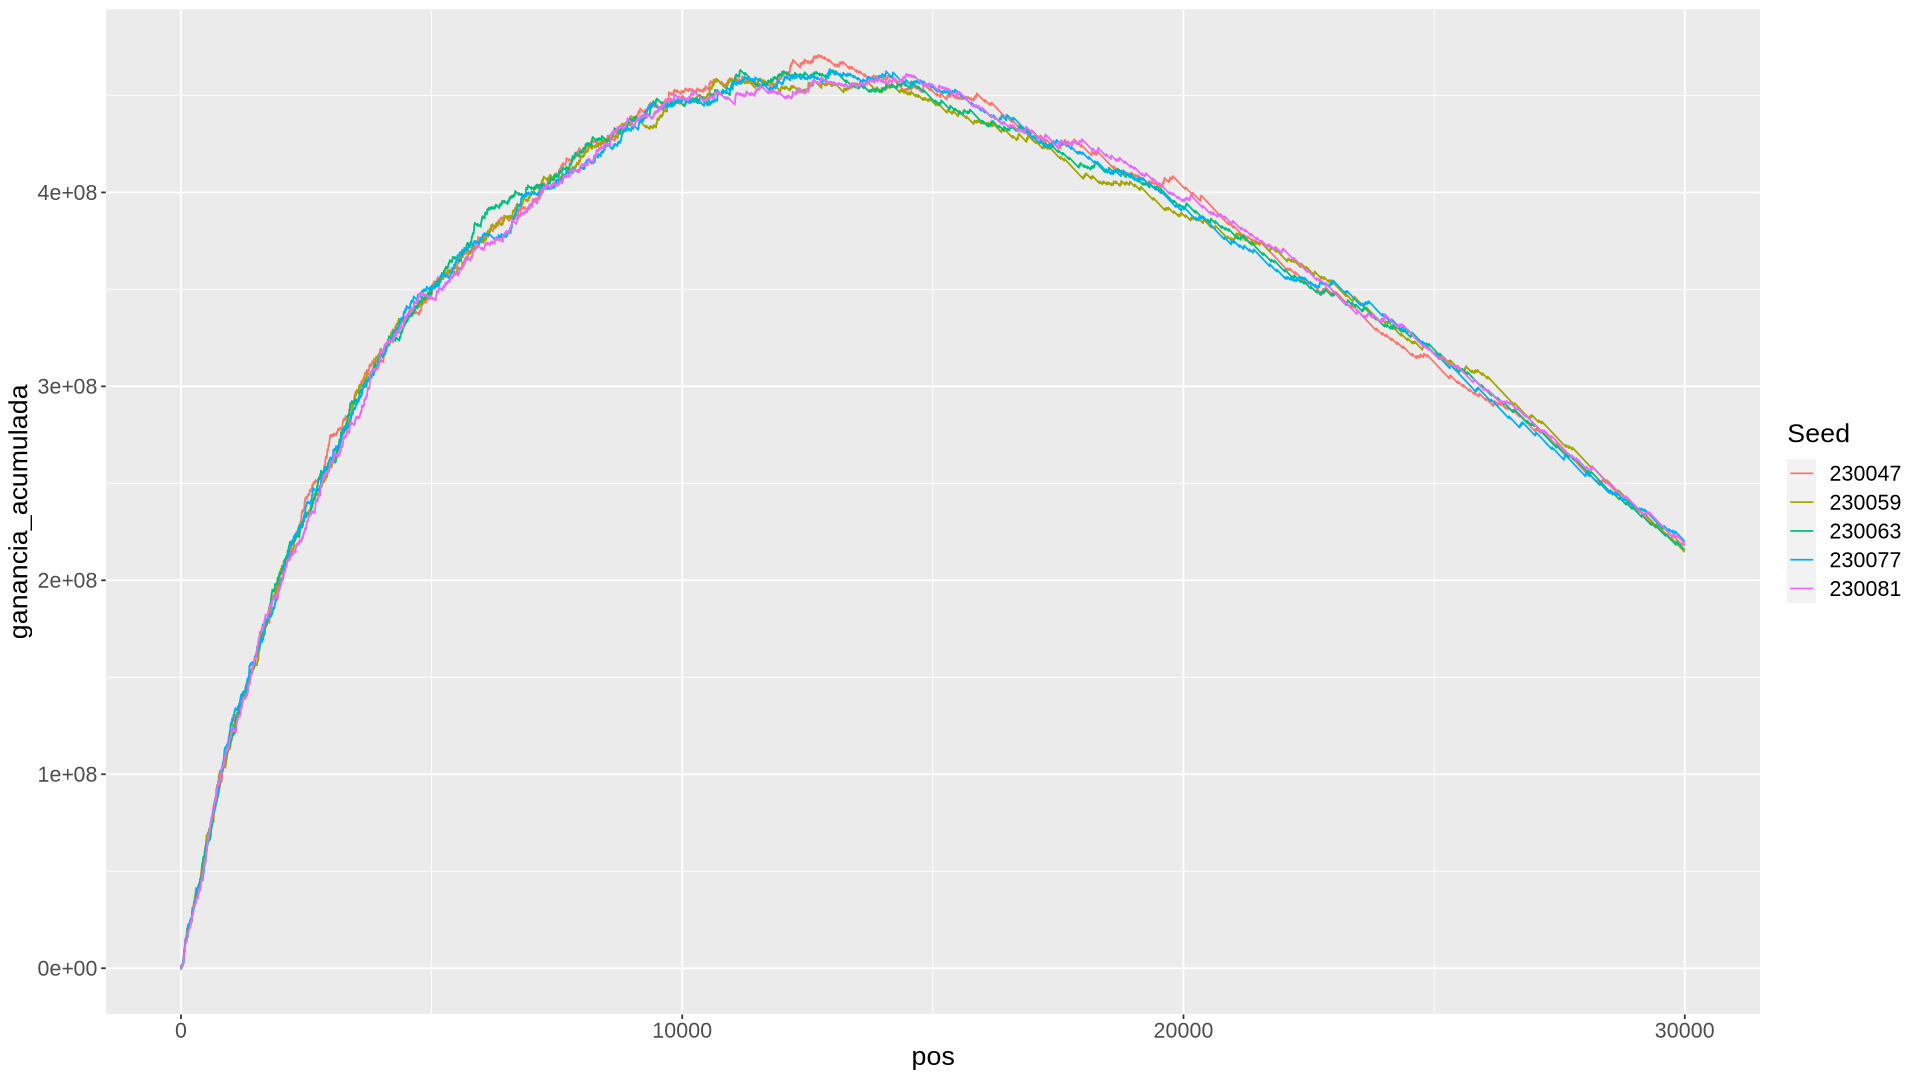

In [21]:
# defino hasta donde muestra el grafico
amostrar <- 30000
# observamos la curva de ganancia
gra <- ggplot(
           data= tb_curvas[pos <= amostrar],
           aes( x= pos, y= ganancia_acumulada, color= factor(seed))
             ) + geom_line() + labs(color = "Seed")

gra <- gra + theme(text = element_text(size = 16))

options(repr.plot.width=16, repr.plot.height=9)
print( gra )


In [22]:
for (envios in cortes) {
  ganancia <- tb_prediccion[1:envios, sum(gan)]
  cat( envios, "\t", ganancia, "\n")
}

4000 	 317900000 
4500 	 336050000 
5000 	 345400000 
5500 	 358050000 
6000 	 370700000 
6500 	 380050000 
7000 	 392700000 
7500 	 403150000 
8000 	 414700000 
8500 	 425150000 
9000 	 435600000 
9500 	 441650000 
10000 	 448800000 
10500 	 448250000 
11000 	 446600000 
11500 	 452650000 
12000 	 449900000 
12500 	 452650000 
13000 	 456500000 
13500 	 455950000 
14000 	 457600000 
14500 	 460350000 
15000 	 455400000 
15500 	 450450000 
16000 	 443300000 
16500 	 433950000 
17000 	 431200000 
17500 	 422950000 
18000 	 426800000 
18500 	 418550000 
19000 	 412500000 


# Guardamos resultados

In [23]:
if (file.exists(archivo_validaciones)) {
  validaciones_previas <- fread(archivo_validaciones)
}

registro_validacion <- data.table(
  id_validacion = id_validacion,
  ganancia = ganancia_promedio,
  seeds = paste(SEEDS, collapse = ","),
  dataset = dataset_file,
  cantidad_registros_totales = nrow(dataset),
  cantidad_registros_entrenamiento = nrow(dataset_train),
  cantidad_registros_validacion = nrow(dfuture),
  meses_entrenamiento = paste(train_final, collapse = ","),
  meses_validacion = paste(future, collapse = ","),
  columnas_excluidas = paste(columnas_excluir, collapse = ","),
  benchmark_original = benchmark_base
)

# Incorpora seeds al histórico anterior si todavía no tiene esa columna.
if (file.exists(archivo_validaciones) && !("seeds" %in% names(validaciones_previas))) {
  validaciones_previas[, seeds := NA_character_]
  setcolorder(validaciones_previas, names(registro_validacion))
  fwrite(validaciones_previas, archivo_validaciones)
}

fwrite(
  registro_validacion,
  archivo_validaciones,
  append = file.exists(archivo_validaciones),
  col.names = !file.exists(archivo_validaciones)
)

# Guarda exactamente los parámetros enviados a lgb.train()
saveRDS(
  params_por_semilla,
  file.path(carpeta_man_val, paste0(id_validacion, ".rds"))
)


# Historico

In [24]:
historico <- fread(archivo_validaciones)
historico

id_validacion,ganancia,seeds,dataset,cantidad_registros_totales,cantidad_registros_entrenamiento,cantidad_registros_validacion,meses_entrenamiento,meses_validacion,columnas_excluidas,benchmark_original
<chr>,<int>,<chr>,<chr>,<int>,<int>,<int>,<chr>,<int>,<chr>,<chr>
62-REPLICA,463534500,"230047,230059,230063,230077,230081",RANKS_LF_O2_K6_P4.csv,983061,326184,164114,"202103,202104",202106,"ternaria,ternaria_lag1,ternaria_lag2,clase01,fold,azar,training,cprestamos_personales,cprestamos_personales_lag1,cprestamos_personales_delta1,cprestamos_personales_lag2,cprestamos_personales_delta2,cprestamos_personales_lag_pond,cprestamos_personales_delta_lag_pond,cprestamos_personales_lag_pond2,cprestamos_personales_delta_lag_pond2,mprestamos_personales,mprestamos_personales_lag1,mprestamos_personales_delta1,mprestamos_personales_lag2,mprestamos_personales_delta2,mprestamos_personales_lag_pond,mprestamos_personales_delta_lag_pond,mprestamos_personales_lag_pond2,mprestamos_personales_delta_lag_pond2",benchmark_multisemilla_lags20261009_200322-r
